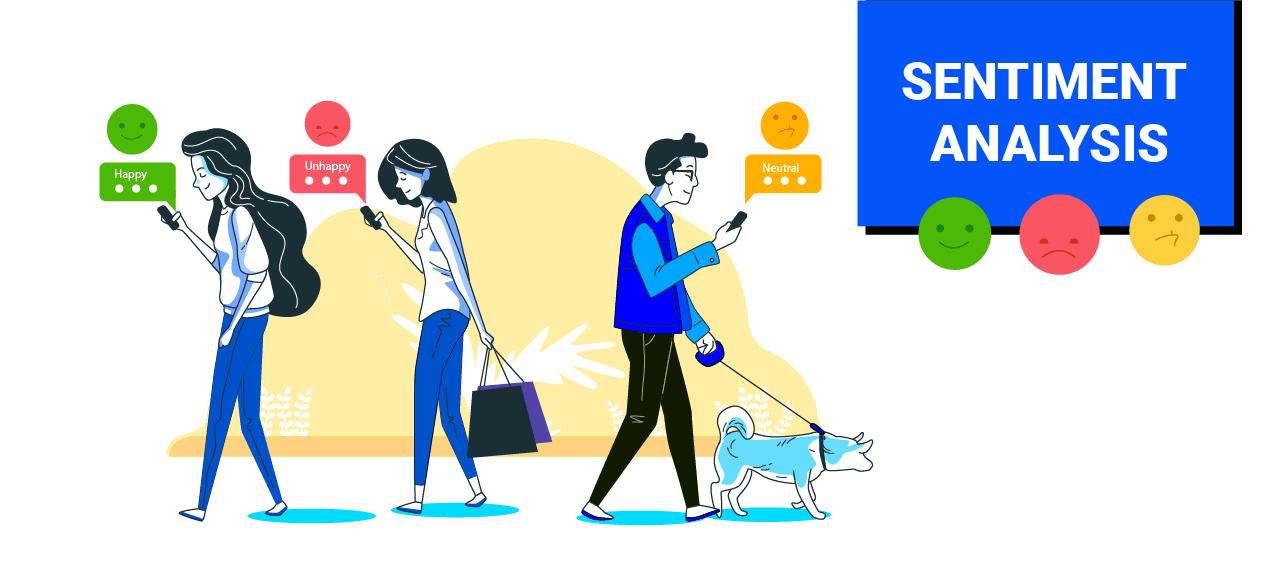

# Textual Emotion Recognition (v1)
**CVIS Hands-on Training Project, BRAC University, Summer 2025.** Faiaz Abrar Zaman Pronoy.

The original submission: Bi-LSTM, 1D CNN and hybrid CNN-LSTM models, combined with five ensemble methods.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from collections import Counter
from wordcloud import WordCloud

import tensorflow as tf

tf.config.run_functions_eagerly(True)
tf.data.experimental.enable_debug_mode()

if not tf.executing_eagerly():
    tf.compat.v1.enable_eager_execution()
    
print(f"✅ TensorFlow {tf.__version__} - Eager: {tf.executing_eagerly()}")

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Embedding, LSTM, Dense, Bidirectional, 
                                      Conv1D, GlobalMaxPooling1D, Dropout, 
                                      Input, Concatenate, Flatten, BatchNormalization)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

from nltk.stem import PorterStemmer
import re

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

✅ TensorFlow 2.18.0 - Eager: True


## 1. Load Dataset

In [31]:
print("\n[1] Loading Dataset...")

train_data = pd.read_csv('data/training.csv')
val_data = pd.read_csv('data/validation.csv')
test_data = pd.read_csv('data/test.csv')

print(f"Original Train: {train_data.shape}")
print(f"Original Validation: {val_data.shape}")
print(f"Original Test: {test_data.shape}")

half_test_data = test_data.iloc[1000:]
test_data = test_data.iloc[:1000]
val_data = pd.concat([val_data, half_test_data], axis=0)

print(f"\nAfter redistribution:")
print(f"Train: {train_data.shape}")
print(f"Validation: {val_data.shape}")
print(f"Test: {test_data.shape}")


[1] Loading Dataset...
Original Train: (16000, 2)
Original Validation: (2000, 2)
Original Test: (2000, 2)

After redistribution:
Train: (16000, 2)
Validation: (3000, 2)
Test: (1000, 2)


## 2. Data Exploration


[2] Data Exploration...

Missing Values:
Train: 0
Val: 0
Test: 0

Class Distribution:
label_name
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


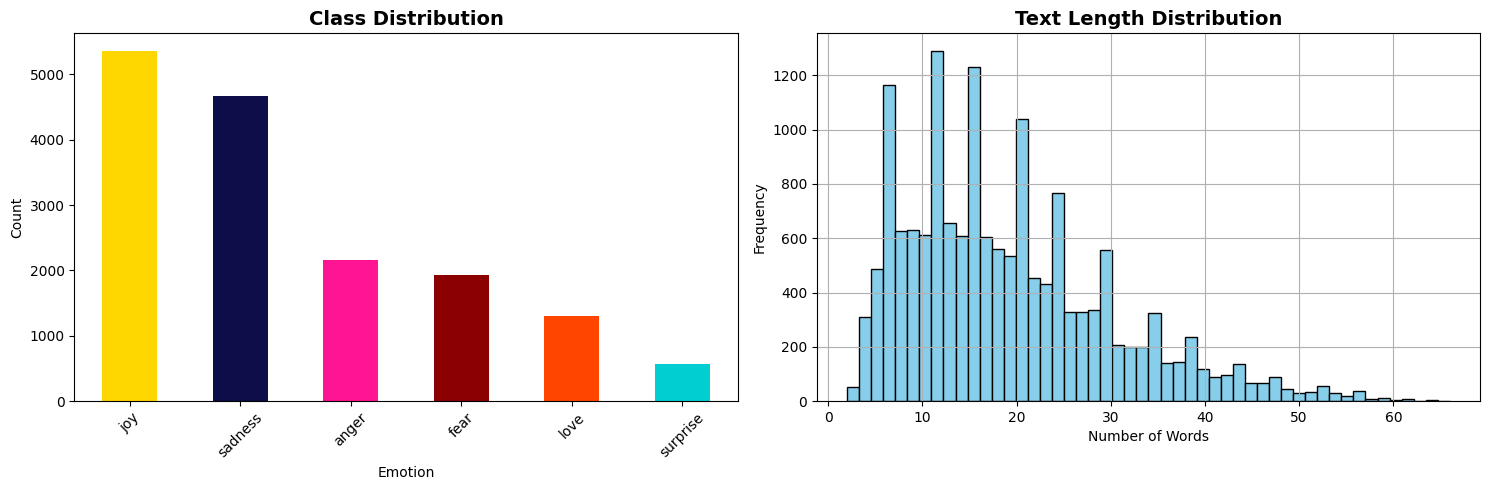


Average text length: 19.17 words
Max text length: 66 words


In [32]:
print("\n[2] Data Exploration...")

print("\nMissing Values:")
print(f"Train: {train_data.isnull().sum().sum()}")
print(f"Val: {val_data.isnull().sum().sum()}")
print(f"Test: {test_data.isnull().sum().sum()}")

labels_dict = {0:'sadness', 1:'joy', 2:'love', 3:'anger', 4:'fear', 5:'surprise'}
train_data['label_name'] = train_data['label'].map(labels_dict)

print("\nClass Distribution:")
print(train_data['label_name'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

train_data['label_name'].value_counts().plot(
    kind='bar', 
    ax=axes[0],
    color=['#FFD700', '#0c0d49', '#FF1493', '#8B0000', '#FF4500', '#00CED1']
)
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Emotion')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

train_data['text_length'] = train_data['text'].apply(lambda x: len(x.split()))
train_data['text_length'].hist(bins=50, ax=axes[1], color='skyblue', edgecolor='black')
axes[1].set_title('Text Length Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f"\nAverage text length: {train_data['text_length'].mean():.2f} words")
print(f"Max text length: {train_data['text_length'].max()} words")

## 3. Text Preprocessing

In [33]:
print("\n[3] Text Preprocessing...")

def clean_text(text):
    """Clean and normalize text"""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = ' '.join(text.split())
    return text

train_data['text'] = train_data['text'].apply(clean_text)
val_data['text'] = val_data['text'].apply(clean_text)
test_data['text'] = test_data['text'].apply(clean_text)

print("Text cleaning completed!")


[3] Text Preprocessing...
Text cleaning completed!


## 4. Tokenization & Stemming

In [34]:
print("\n[4] Tokenization and Stemming...")

all_texts = train_data['text'].tolist() + val_data['text'].tolist() + test_data['text'].tolist()

stemmer = PorterStemmer()

def stem_text(text):
    words = text.split()
    stemmed = [stemmer.stem(word) for word in words]
    return ' '.join(stemmed)

train_data['text_stemmed'] = train_data['text'].apply(stem_text)
val_data['text_stemmed'] = val_data['text'].apply(stem_text)
test_data['text_stemmed'] = test_data['text'].apply(stem_text)

MAX_WORDS = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(train_data['text_stemmed'])

X_train = tokenizer.texts_to_sequences(train_data['text_stemmed'])
X_val = tokenizer.texts_to_sequences(val_data['text_stemmed'])
X_test = tokenizer.texts_to_sequences(test_data['text_stemmed'])

X_train = pad_sequences(X_train, maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(X_val, maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(X_test, maxlen=MAX_LEN, padding='post', truncating='post')


y_train = train_data['label'].values
y_val = val_data['label'].values
y_test = test_data['label'].values

NUM_CLASSES = 6
y_train_cat = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_cat = to_categorical(y_val, num_classes=NUM_CLASSES)
y_test_cat = to_categorical(y_test, num_classes=NUM_CLASSES)

print(f"\nVocabulary Size: {len(tokenizer.word_index)}")
print(f"Using TOP {MAX_WORDS} words")
print(f"Sequence Length: {MAX_LEN}")
print(f"\nX_train shape: {X_train.shape}")
print(f"y_train shape: {y_train_cat.shape}")


[4] Tokenization and Stemming...

Vocabulary Size: 10489
Using TOP 10000 words
Sequence Length: 100

X_train shape: (16000, 100)
y_train shape: (16000, 6)


## 5. Model Architectures

In [35]:
print("\n[5] Building Models...")

EMBEDDING_DIM = 128

def build_lstm_model():
    model = Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM),
        Bidirectional(LSTM(128, return_sequences=True)),
        Dropout(0.3),
        Bidirectional(LSTM(64)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    return model

def build_cnn_model():
    model = Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM),
        Conv1D(128, 5, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    return model

def build_hybrid_model():
    model = Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM),
        Conv1D(128, 5, activation='relu'),
        Dropout(0.3),
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    return model


lstm_model = build_lstm_model()
lstm_model.build(input_shape=(None, MAX_LEN))

cnn_model = build_cnn_model()
cnn_model.build(input_shape=(None, MAX_LEN))

hybrid_model = build_hybrid_model()
hybrid_model.build(input_shape=(None, MAX_LEN))

print("\nModel 1: Bi-LSTM")
lstm_model.summary()
print("\nModel 2: 1D CNN")
cnn_model.summary()
print("\nModel 3: Hybrid CNN-LSTM")
hybrid_model.summary()


[5] Building Models...

Model 1: Bi-LSTM


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 100, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 100, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,716,166 (6.55 MB)

 Trainable params: 1,716,166 (6.55 MB)

...

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 96, 128)        │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 96, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,469,510 (5.61 MB)

 Trainable params: 1,469,510 (5.61 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile Models

In [36]:
print("\n[6] Compiling Models...")

lstm_model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)
print("✅ LSTM model compiled")

cnn_model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)
print("✅ CNN model compiled")

hybrid_model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)
print("✅ Hybrid model compiled")

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)


[6] Compiling Models...
✅ LSTM model compiled
✅ CNN model compiled
✅ Hybrid model compiled


## 7. Train Models

In [37]:
print("\n[7] Training Models...")

EPOCHS = 30
BATCH_SIZE = 64

print("\n>>> Training LSTM Model...")
history_lstm = lstm_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\n>>> Training CNN Model...")
history_cnn = cnn_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\n>>> Training Hybrid CNN-LSTM Model...")
history_hybrid = hybrid_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


[7] Training Models...

>>> Training LSTM Model...
Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 47s 187ms/step - accuracy: 0.3782 - loss: 1.5360 - val_accuracy: 0.7267 - val_loss: 0.7592 - learning_rate: 0.0010
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 47s 187ms/step - accuracy: 0.7978 - loss: 0.5858 - val_accuracy: 0.8897 - val_loss: 0.3297 - learning_rate: 0.0010
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 186ms/step - accuracy: 0.9224 - loss: 0.2429 - val_accuracy: 0.8987 - val_loss: 0.2963 - learning_rate: 0.0010
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 186ms/step - accuracy: 0.9471 - loss: 0.1595 - val_accuracy: 0.8960 - val_loss: 0.3188 - learning_rate: 0.0010
Epoch 5/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 186ms/step - accuracy: 0.9510 - loss: 0.1400 - val_accuracy: 0.8897 - val_loss: 0.3473 - learning_rate: 0.0010
Epoch 6/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 186ms/step - accuracy: 0.9601 - loss: 0.1132 - val_accuracy: 0.8963 - val_loss: 0.3416 - learning_rate: 0.0010
Epoch 7/30
250/250

## 8. Evaluation

In [38]:
print("\n[8] Model Evaluation...")

test_loss_lstm, test_acc_lstm = lstm_model.evaluate(X_test, y_test_cat, verbose=0)
test_loss_cnn, test_acc_cnn = cnn_model.evaluate(X_test, y_test_cat, verbose=0)
test_loss_hybrid, test_acc_hybrid = hybrid_model.evaluate(X_test, y_test_cat, verbose=0)

print("\n" + "=" * 60)
print("TEST SET RESULTS")
print("=" * 60)
print(f"LSTM Model      - Loss: {test_loss_lstm:.4f} | Accuracy: {test_acc_lstm:.4f}")
print(f"CNN Model       - Loss: {test_loss_cnn:.4f} | Accuracy: {test_acc_cnn:.4f}")
print(f"Hybrid Model    - Loss: {test_loss_hybrid:.4f} | Accuracy: {test_acc_hybrid:.4f}")
print("=" * 60)


[8] Model Evaluation...

TEST SET RESULTS
LSTM Model      - Loss: 0.3005 | Accuracy: 0.8810
CNN Model       - Loss: 0.2850 | Accuracy: 0.8900
Hybrid Model    - Loss: 0.3630 | Accuracy: 0.8900


## 9. Visualization


[9] Generating Visualizations...


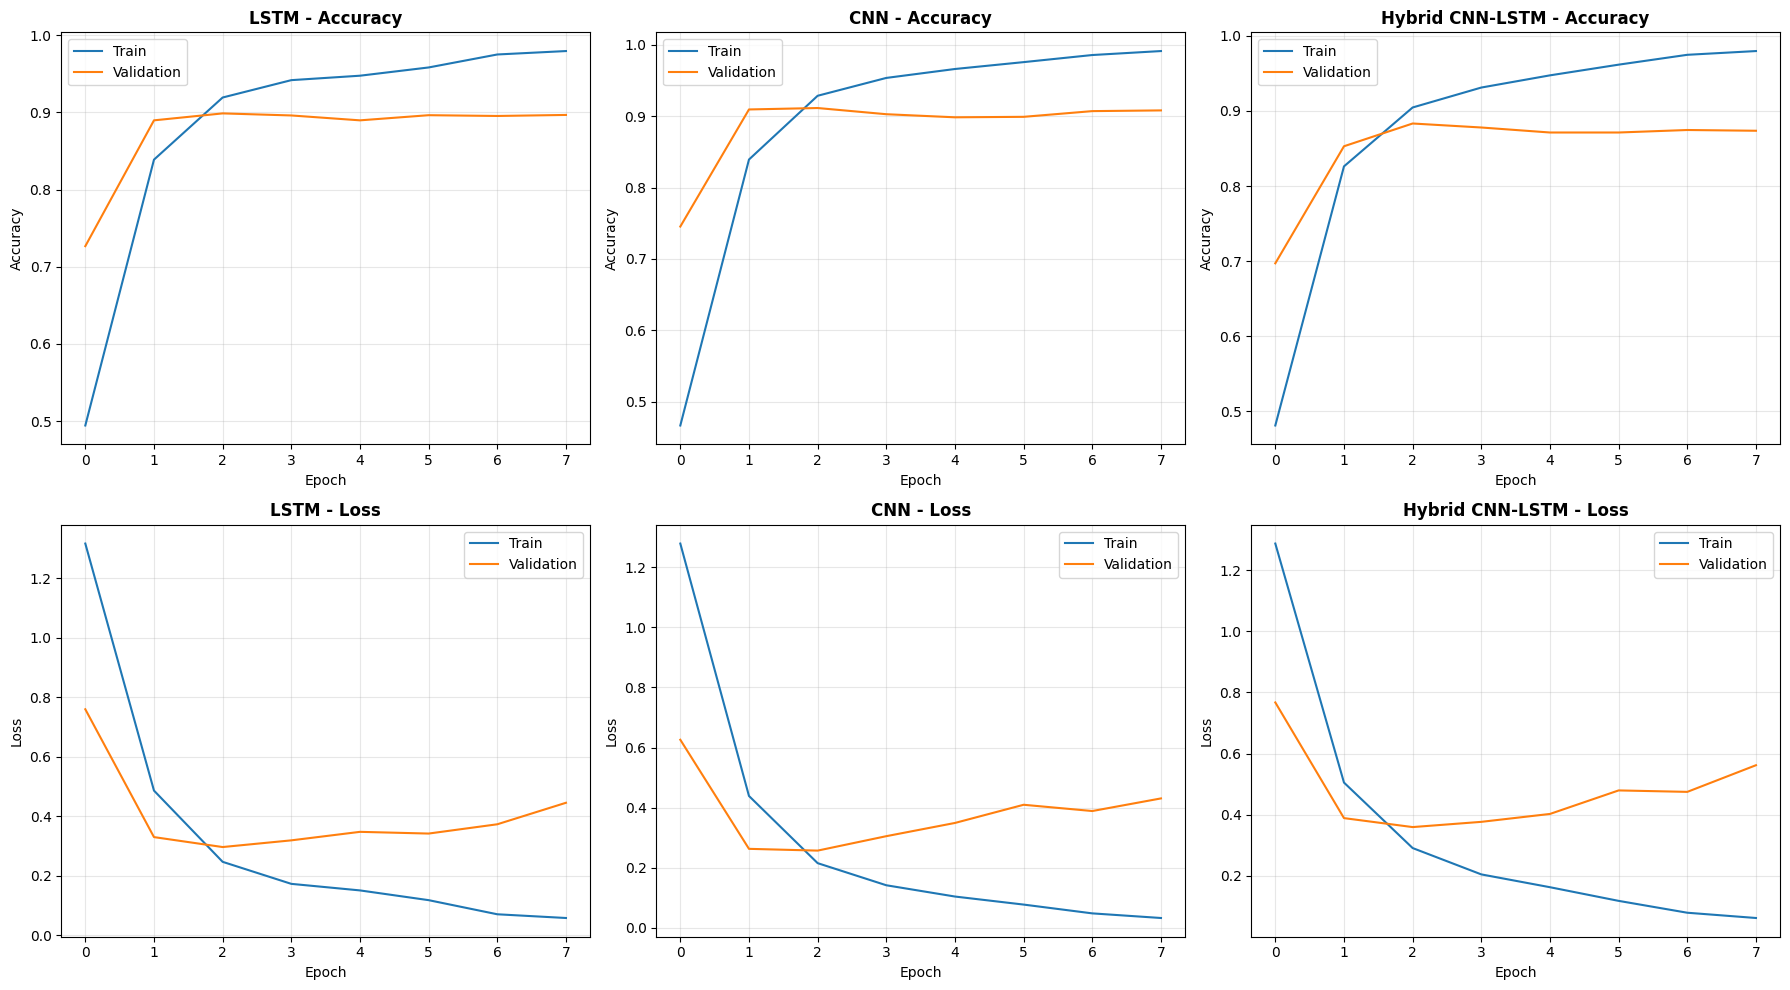

In [39]:
print("\n[9] Generating Visualizations...")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].plot(history_lstm.history['accuracy'], label='Train')
axes[0, 0].plot(history_lstm.history['val_accuracy'], label='Validation')
axes[0, 0].set_title('LSTM - Accuracy', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[1, 0].plot(history_lstm.history['loss'], label='Train')
axes[1, 0].plot(history_lstm.history['val_loss'], label='Validation')
axes[1, 0].set_title('LSTM - Loss', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[0, 1].plot(history_cnn.history['accuracy'], label='Train')
axes[0, 1].plot(history_cnn.history['val_accuracy'], label='Validation')
axes[0, 1].set_title('CNN - Accuracy', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 1].plot(history_cnn.history['loss'], label='Train')
axes[1, 1].plot(history_cnn.history['val_loss'], label='Validation')
axes[1, 1].set_title('CNN - Loss', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)


axes[0, 2].plot(history_hybrid.history['accuracy'], label='Train')
axes[0, 2].plot(history_hybrid.history['val_accuracy'], label='Validation')
axes[0, 2].set_title('Hybrid CNN-LSTM - Accuracy', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Accuracy')
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

axes[1, 2].plot(history_hybrid.history['loss'], label='Train')
axes[1, 2].plot(history_hybrid.history['val_loss'], label='Validation')
axes[1, 2].set_title('Hybrid CNN-LSTM - Loss', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Loss')
axes[1, 2].legend()
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Model Comparison Bar Chart

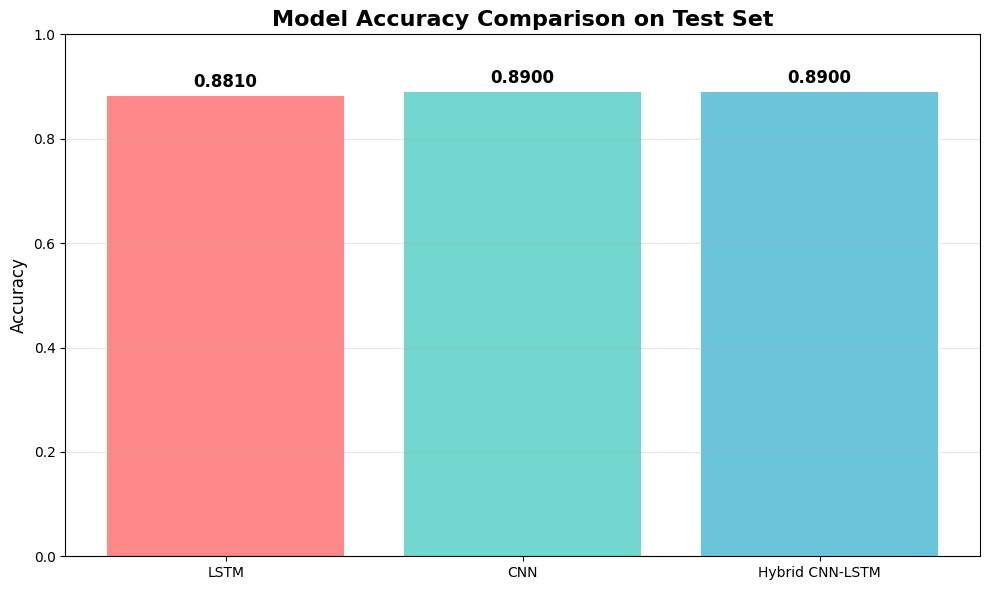

In [40]:
models_names = ['LSTM', 'CNN', 'Hybrid CNN-LSTM']
accuracies = [test_acc_lstm, test_acc_cnn, test_acc_hybrid]

plt.figure(figsize=(10, 6))
bars = plt.bar(models_names, accuracies, color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.8)
plt.title('Model Accuracy Comparison on Test Set', fontsize=16, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12)
plt.ylim([0, 1])
plt.grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{acc:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Confusion Matrices


[11] Generating Confusion Matrices...
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step


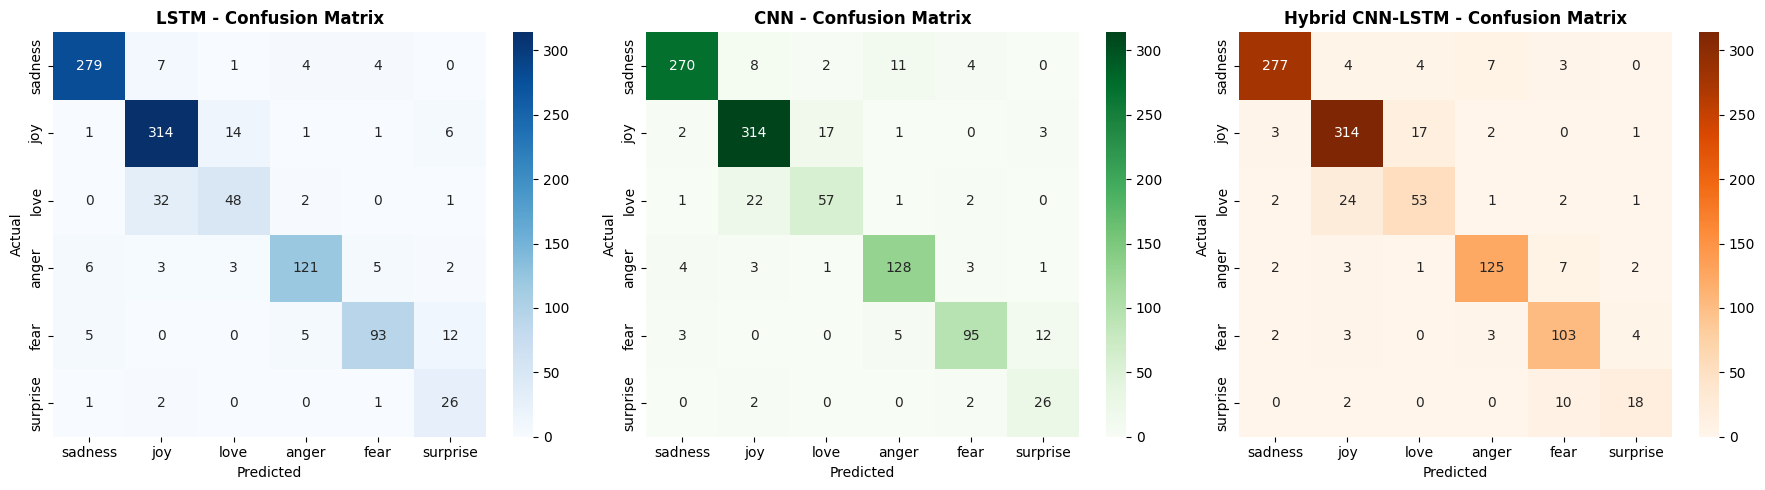

In [41]:
print("\n[11] Generating Confusion Matrices...")

y_pred_lstm = np.argmax(lstm_model.predict(X_test), axis=1)
y_pred_cnn = np.argmax(cnn_model.predict(X_test), axis=1)
y_pred_hybrid = np.argmax(hybrid_model.predict(X_test), axis=1)

cm_lstm = confusion_matrix(y_test, y_pred_lstm)
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
cm_hybrid = confusion_matrix(y_test, y_pred_hybrid)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

emotion_labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=emotion_labels, yticklabels=emotion_labels, ax=axes[0])
axes[0].set_title('LSTM - Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens', 
            xticklabels=emotion_labels, yticklabels=emotion_labels, ax=axes[1])
axes[1].set_title('CNN - Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(cm_hybrid, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=emotion_labels, yticklabels=emotion_labels, ax=axes[2])
axes[2].set_title('Hybrid CNN-LSTM - Confusion Matrix', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 12. Classification Reports

In [42]:
print("\n[12] Classification Reports...")

print("\n" + "=" * 60)
print("LSTM MODEL - Classification Report")
print("=" * 60)
print(classification_report(y_test, y_pred_lstm, target_names=emotion_labels))

print("\n" + "=" * 60)
print("CNN MODEL - Classification Report")
print("=" * 60)
print(classification_report(y_test, y_pred_cnn, target_names=emotion_labels))

print("\n" + "=" * 60)
print("HYBRID MODEL - Classification Report")
print("=" * 60)
print(classification_report(y_test, y_pred_hybrid, target_names=emotion_labels))


[12] Classification Reports...

LSTM MODEL - Classification Report
              precision    recall  f1-score   support

     sadness       0.96      0.95      0.95       295
         joy       0.88      0.93      0.90       337
        love       0.73      0.58      0.64        83
       anger       0.91      0.86      0.89       140
        fear       0.89      0.81      0.85       115
    surprise       0.55      0.87      0.68        30

    accuracy                           0.88      1000
   macro avg       0.82      0.83      0.82      1000
weighted avg       0.88      0.88      0.88      1000


CNN MODEL - Classification Report
              precision    recall  f1-score   support

     sadness       0.96      0.92      0.94       295
         joy       0.90      0.93      0.92       337
        love       0.74      0.69      0.71        83
       anger       0.88      0.91      0.90       140
        fear       0.90      0.83      0.86       115
    surprise       0.62      

## 13. Prediction Examples

In [43]:
print("\n[13] Sample Predictions...")

def predict_emotion(text, model, model_name):
    """Predict emotion for a given text"""
    cleaned = clean_text(text)
    stemmed = stem_text(cleaned)
    
    sequence = tokenizer.texts_to_sequences([stemmed])
    padded = pad_sequences(sequence, maxlen=MAX_LEN, padding='post')
    
    prediction = model.predict(padded, verbose=0)
    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction)
    
    return labels_dict[predicted_class], confidence

print("\n" + "=" * 60)
print("SAMPLE PREDICTIONS")
print("=" * 60)

for i in range(5):
    idx = random.randint(0, len(test_data)-1)
    text = test_data.iloc[idx]['text']
    actual = labels_dict[test_data.iloc[idx]['label']]
    
    lstm_pred, lstm_conf = predict_emotion(text, lstm_model, "LSTM")
    cnn_pred, cnn_conf = predict_emotion(text, cnn_model, "CNN")
    hybrid_pred, hybrid_conf = predict_emotion(text, hybrid_model, "Hybrid")
    
    print(f"\nSample {i+1}:")
    print(f"Text: {text[:80]}...")
    print(f"Actual: {actual}")
    print(f"LSTM Prediction: {lstm_pred} (confidence: {lstm_conf:.2f})")
    print(f"CNN Prediction: {cnn_pred} (confidence: {cnn_conf:.2f})")
    print(f"Hybrid Prediction: {hybrid_pred} (confidence: {hybrid_conf:.2f})")
    print("-" * 60)


[13] Sample Predictions...

SAMPLE PREDICTIONS

Sample 1:
Text: im not sure how i feel about needing to exercise so as to maintain a pleasant de...
Actual: joy
LSTM Prediction: joy (confidence: 1.00)
CNN Prediction: joy (confidence: 1.00)
Hybrid Prediction: joy (confidence: 0.99)
------------------------------------------------------------

Sample 2:
Text: im not sure how i feel more than anything im keen to see it as a test to see if ...
Actual: joy
LSTM Prediction: joy (confidence: 1.00)
CNN Prediction: joy (confidence: 1.00)
Hybrid Prediction: joy (confidence: 1.00)
------------------------------------------------------------

Sample 3:
Text: i am feeling much more relaxed...
Actual: joy
LSTM Prediction: joy (confidence: 1.00)
CNN Prediction: joy (confidence: 1.00)
Hybrid Prediction: joy (confidence: 0.99)
------------------------------------------------------------

Sample 4:
Text: i am feeling energized productive and creative...
Actual: joy
LSTM Prediction: joy (confidence: 1.00

## 14. Final Summary

In [44]:
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
print(f"Dataset Size: {len(train_data)} train, {len(val_data)} val, {len(test_data)} test")
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"\nBest Model: ", end="")

best_acc = max(test_acc_lstm, test_acc_cnn, test_acc_hybrid)
if best_acc == test_acc_lstm:
    print(f"LSTM ({test_acc_lstm:.4f})")
elif best_acc == test_acc_cnn:
    print(f"CNN ({test_acc_cnn:.4f})")
else:
    print(f"Hybrid CNN-LSTM ({test_acc_hybrid:.4f})")


FINAL SUMMARY
Dataset Size: 16000 train, 3000 val, 1000 test
Vocabulary Size: 10489
Number of Classes: 6

Best Model: CNN (0.8900)


## Ensemble Methods: Combining the LSTM, CNN and Hybrid Models

ENSEMBLE METHODS FOR EMOTION DETECTION

[METHOD 1] Voting Ensemble...
✅ Hard Voting Accuracy: 0.8980
✅ Soft Voting Accuracy: 0.8970

[METHOD 2] Weighted Ensemble...
Model Weights: LSTM=0.881, CNN=0.890, Hybrid=0.890
✅ Weighted Ensemble Accuracy: 0.8970

[METHOD 3] Stacking Ensemble...
✅ Stacking (Logistic Regression): 0.8950
✅ Stacking (Random Forest): 0.8930

[METHOD 4] Simple Averaging...
✅ Simple Averaging Accuracy: 0.8970

[METHOD 5] Max Confidence Ensemble...
✅ Max Confidence Accuracy: 0.8920

ENSEMBLE METHODS COMPARISON

📊 Individual Models:
   LSTM           : 0.8810
   CNN            : 0.8900
   Hybrid         : 0.8900

🎯 Ensemble Methods:
   Hard Voting         : 0.8980
   Soft Voting         : 0.8970
   Weighted            : 0.8970
   Averaging           : 0.8970
   Max Confidence      : 0.8920
   Stacking (LR)       : 0.8950
   Stacking (RF)       : 0.8930

🏆 BEST METHOD: Hard Voting (0.8980)

[Generating Visualizations...]


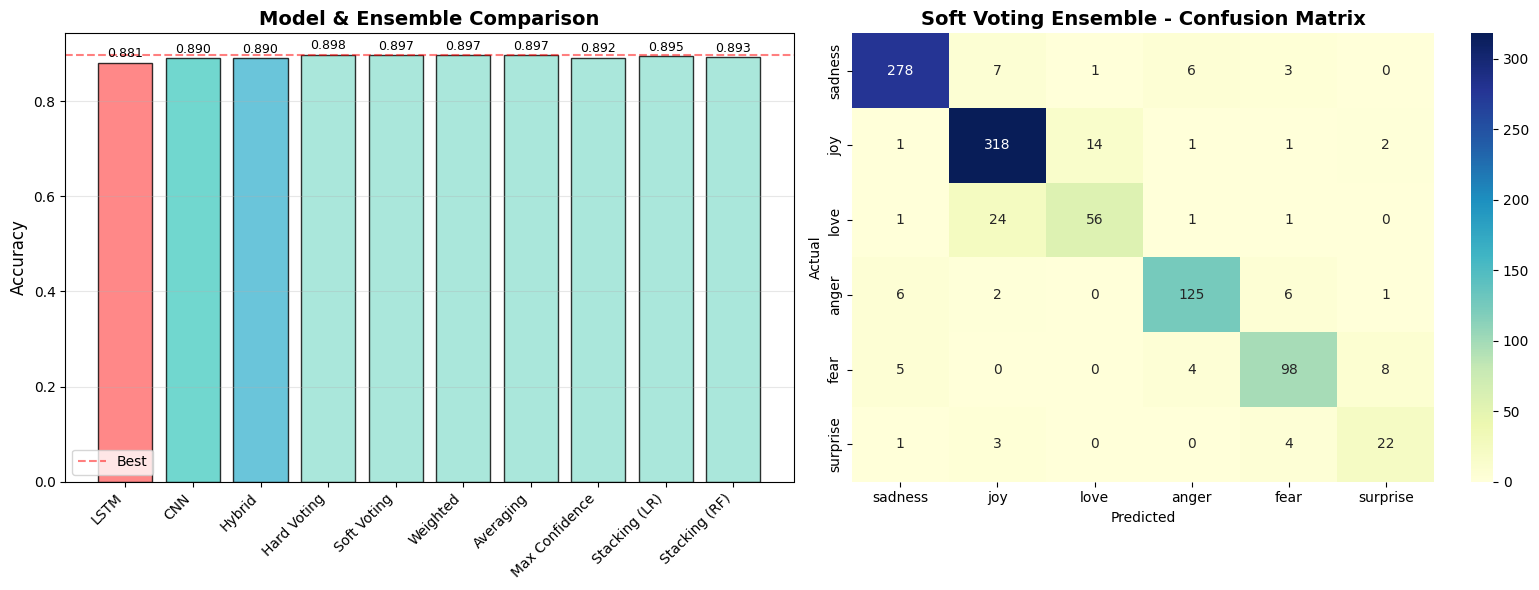


BEST ENSEMBLE - CLASSIFICATION REPORT

Soft Voting Ensemble:
              precision    recall  f1-score   support

     sadness       0.95      0.94      0.95       295
         joy       0.90      0.94      0.92       337
        love       0.79      0.67      0.73        83
       anger       0.91      0.89      0.90       140
        fear       0.87      0.85      0.86       115
    surprise       0.67      0.73      0.70        30

    accuracy                           0.90      1000
   macro avg       0.85      0.84      0.84      1000
weighted avg       0.90      0.90      0.90      1000


TESTING ENSEMBLE PREDICTION FUNCTION

Text: 'I am so happy today!'
Emotion: joy (confidence: 0.93)

Text: 'This makes me very angry'
Emotion: anger (confidence: 0.98)

Text: 'I'm feeling a bit sad'
Emotion: sadness (confidence: 0.86)

Text: 'I love this so much'
Emotion: love (confidence: 0.41)

Text: 'This is terrifying'
Emotion: fear (confidence: 0.96)

Text: 'Wow, that's amazing!'
Emotion

In [45]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("ENSEMBLE METHODS FOR EMOTION DETECTION")
print("=" * 60)

print("\n[METHOD 1] Voting Ensemble...")

def voting_ensemble(models, X_data, method='hard'):
    """
    Voting Ensemble: Models vote for prediction
    
    Args:
        models: List of trained models
        X_data: Input data
        method: 'hard' (majority vote) or 'soft' (average probabilities)
    """
    predictions = []
    
    for model in models:
        pred = model.predict(X_data, verbose=0)
        predictions.append(pred)
    
    predictions = np.array(predictions)
    
    if method == 'hard':
        class_predictions = np.argmax(predictions, axis=2)
        final_pred = []
        
        for i in range(predictions.shape[1]):
            votes = class_predictions[:, i]
            final_pred.append(np.bincount(votes).argmax())
        
        return np.array(final_pred)
    
    elif method == 'soft':
        avg_probabilities = np.mean(predictions, axis=0)
        return np.argmax(avg_probabilities, axis=1)


models_list = [lstm_model, cnn_model, hybrid_model]

y_pred_hard = voting_ensemble(models_list, X_test, method='hard')
acc_hard = accuracy_score(y_test, y_pred_hard)

y_pred_soft = voting_ensemble(models_list, X_test, method='soft')
acc_soft = accuracy_score(y_test, y_pred_soft)

print(f"✅ Hard Voting Accuracy: {acc_hard:.4f}")
print(f"✅ Soft Voting Accuracy: {acc_soft:.4f}")

print("\n[METHOD 2] Weighted Ensemble...")

def weighted_ensemble(models, X_data, weights):
    """
    Weighted Ensemble: Give more weight to better models
    
    Args:
        models: List of trained models
        X_data: Input data
        weights: List of weights for each model
    """
    predictions = []
    
    for model in models:
        pred = model.predict(X_data, verbose=0)
        predictions.append(pred)
    
    predictions = np.array(predictions)
    
    weights = np.array(weights)
    weights = weights / weights.sum()
    
    weighted_pred = np.zeros_like(predictions[0])
    for i, weight in enumerate(weights):
        weighted_pred += predictions[i] * weight
    
    return np.argmax(weighted_pred, axis=1)


weights_accuracy = [test_acc_lstm, test_acc_cnn, test_acc_hybrid]
y_pred_weighted = weighted_ensemble(models_list, X_test, weights_accuracy)
acc_weighted = accuracy_score(y_test, y_pred_weighted)

print(f"Model Weights: LSTM={weights_accuracy[0]:.3f}, CNN={weights_accuracy[1]:.3f}, Hybrid={weights_accuracy[2]:.3f}")
print(f"✅ Weighted Ensemble Accuracy: {acc_weighted:.4f}")

print("\n[METHOD 3] Stacking Ensemble...")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def stacking_ensemble(models, X_train, y_train, X_test, meta_model='lr'):
    """
    Stacking: Train a meta-model on predictions of base models
    
    Args:
        models: List of base models
        X_train, y_train: Training data
        X_test: Test data
        meta_model: 'lr' (Logistic Regression) or 'rf' (Random Forest)
    """
    train_predictions = []
    for model in models:
        pred = model.predict(X_train, verbose=0)
        train_predictions.append(pred)
    
    X_meta_train = np.hstack(train_predictions)
    
    if meta_model == 'lr':
        meta_clf = LogisticRegression(max_iter=1000, random_state=42)
    else:
        meta_clf = RandomForestClassifier(n_estimators=100, random_state=42)
    
    meta_clf.fit(X_meta_train, y_train)
    
    test_predictions = []
    for model in models:
        pred = model.predict(X_test, verbose=0)
        test_predictions.append(pred)
    
    X_meta_test = np.hstack(test_predictions)
    
    return meta_clf.predict(X_meta_test)


y_pred_stack_lr = stacking_ensemble(models_list, X_train, y_train, X_test, meta_model='lr')
acc_stack_lr = accuracy_score(y_test, y_pred_stack_lr)

y_pred_stack_rf = stacking_ensemble(models_list, X_train, y_train, X_test, meta_model='rf')
acc_stack_rf = accuracy_score(y_test, y_pred_stack_rf)

print(f"✅ Stacking (Logistic Regression): {acc_stack_lr:.4f}")
print(f"✅ Stacking (Random Forest): {acc_stack_rf:.4f}")

print("\n[METHOD 4] Simple Averaging...")

def averaging_ensemble(models, X_data):
    """Simple average of all model predictions"""
    predictions = []
    
    for model in models:
        pred = model.predict(X_data, verbose=0)
        predictions.append(pred)
    
    avg_pred = np.mean(predictions, axis=0)
    return np.argmax(avg_pred, axis=1)


y_pred_avg = averaging_ensemble(models_list, X_test)
acc_avg = accuracy_score(y_test, y_pred_avg)

print(f"✅ Simple Averaging Accuracy: {acc_avg:.4f}")

print("\n[METHOD 5] Max Confidence Ensemble...")

def max_confidence_ensemble(models, X_data):
    """
    Pick prediction from model with highest confidence
    """
    all_predictions = []
    all_confidences = []
    
    for model in models:
        pred = model.predict(X_data, verbose=0)
        all_predictions.append(np.argmax(pred, axis=1))
        all_confidences.append(np.max(pred, axis=1))
    
    all_predictions = np.array(all_predictions)
    all_confidences = np.array(all_confidences)
    
    final_predictions = []
    for i in range(all_predictions.shape[1]):
        best_model_idx = np.argmax(all_confidences[:, i])
        final_predictions.append(all_predictions[best_model_idx, i])
    
    return np.array(final_predictions)


y_pred_maxconf = max_confidence_ensemble(models_list, X_test)
acc_maxconf = accuracy_score(y_test, y_pred_maxconf)

print(f"✅ Max Confidence Accuracy: {acc_maxconf:.4f}")

print("\n" + "=" * 60)
print("ENSEMBLE METHODS COMPARISON")
print("=" * 60)

results = {
    'Individual Models': {
        'LSTM': test_acc_lstm,
        'CNN': test_acc_cnn,
        'Hybrid': test_acc_hybrid
    },
    'Ensemble Methods': {
        'Hard Voting': acc_hard,
        'Soft Voting': acc_soft,
        'Weighted': acc_weighted,
        'Averaging': acc_avg,
        'Max Confidence': acc_maxconf,
        'Stacking (LR)': acc_stack_lr,
        'Stacking (RF)': acc_stack_rf
    }
}

print("\n📊 Individual Models:")
for name, acc in results['Individual Models'].items():
    print(f"   {name:15s}: {acc:.4f}")

print("\n🎯 Ensemble Methods:")
for name, acc in results['Ensemble Methods'].items():
    print(f"   {name:20s}: {acc:.4f}")

all_methods = {**results['Individual Models'], **results['Ensemble Methods']}
best_method = max(all_methods.items(), key=lambda x: x[1])
print(f"\n🏆 BEST METHOD: {best_method[0]} ({best_method[1]:.4f})")

print("\n[Generating Visualizations...]")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

methods = list(results['Individual Models'].keys()) + list(results['Ensemble Methods'].keys())
accuracies = list(results['Individual Models'].values()) + list(results['Ensemble Methods'].values())

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1'] + ['#95E1D3'] * len(results['Ensemble Methods'])

bars = axes[0].bar(range(len(methods)), accuracies, color=colors, alpha=0.8, edgecolor='black')
axes[0].set_xticks(range(len(methods)))
axes[0].set_xticklabels(methods, rotation=45, ha='right')
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Model & Ensemble Comparison', fontsize=14, fontweight='bold')
axes[0].axhline(y=max(accuracies), color='red', linestyle='--', alpha=0.5, label='Best')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.005,
                 f'{acc:.3f}', ha='center', va='bottom', fontsize=9)

emotion_labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
cm_ensemble = confusion_matrix(y_test, y_pred_soft)

sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=emotion_labels, yticklabels=emotion_labels, ax=axes[1])
axes[1].set_title('Soft Voting Ensemble - Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("BEST ENSEMBLE - CLASSIFICATION REPORT")
print("=" * 60)

print("\nSoft Voting Ensemble:")
print(classification_report(y_test, y_pred_soft, target_names=emotion_labels))

def predict_emotion_ensemble(text, models, tokenizer, method='soft'):
    """
    Production-ready ensemble prediction function
    
    Args:
        text: Input text string
        models: List of trained models
        tokenizer: Fitted tokenizer
        method: 'soft', 'hard', or 'weighted'
    
    Returns:
        emotion: Predicted emotion
        confidence: Prediction confidence
    """
    def clean_text(text):
        import re
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\s]', '', text)
        text = ' '.join(text.split())
        return text
    
    def stem_text(text):
        from nltk.stem import PorterStemmer
        stemmer = PorterStemmer()
        words = text.split()
        stemmed = [stemmer.stem(word) for word in words]
        return ' '.join(stemmed)
    
    cleaned = clean_text(text)
    stemmed = stem_text(cleaned)
    sequence = tokenizer.texts_to_sequences([stemmed])
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    padded = pad_sequences(sequence, maxlen=100, padding='post')
    
    predictions = []
    for model in models:
        pred = model.predict(padded, verbose=0)
        predictions.append(pred[0])
    
    predictions = np.array(predictions)
    
    if method == 'soft':
        final_pred = np.mean(predictions, axis=0)
    elif method == 'hard':
        class_preds = np.argmax(predictions, axis=1)
        final_class = np.bincount(class_preds).argmax()
        final_pred = np.zeros(6)
        final_pred[final_class] = 1.0
    
    emotion_idx = np.argmax(final_pred)
    confidence = final_pred[emotion_idx]
    
    labels_dict = {0:'sadness', 1:'joy', 2:'love', 3:'anger', 4:'fear', 5:'surprise'}
    
    return labels_dict[emotion_idx], confidence


print("\n" + "=" * 60)
print("TESTING ENSEMBLE PREDICTION FUNCTION")
print("=" * 60)

test_texts = [
    "I am so happy today!",
    "This makes me very angry",
    "I'm feeling a bit sad",
    "I love this so much",
    "This is terrifying",
    "Wow, that's amazing!"
]

for text in test_texts:
    emotion, conf = predict_emotion_ensemble(text, models_list, tokenizer, method='soft')
    print(f"\nText: '{text}'")
    print(f"Emotion: {emotion} (confidence: {conf:.2f})")

print("\n" + "=" * 60)
print("✅ ENSEMBLE IMPLEMENTATION COMPLETE!")
print("=" * 60)


GENERATING ADDITIONAL VISUALIZATIONS

[1] Creating Word Clouds per Emotion...


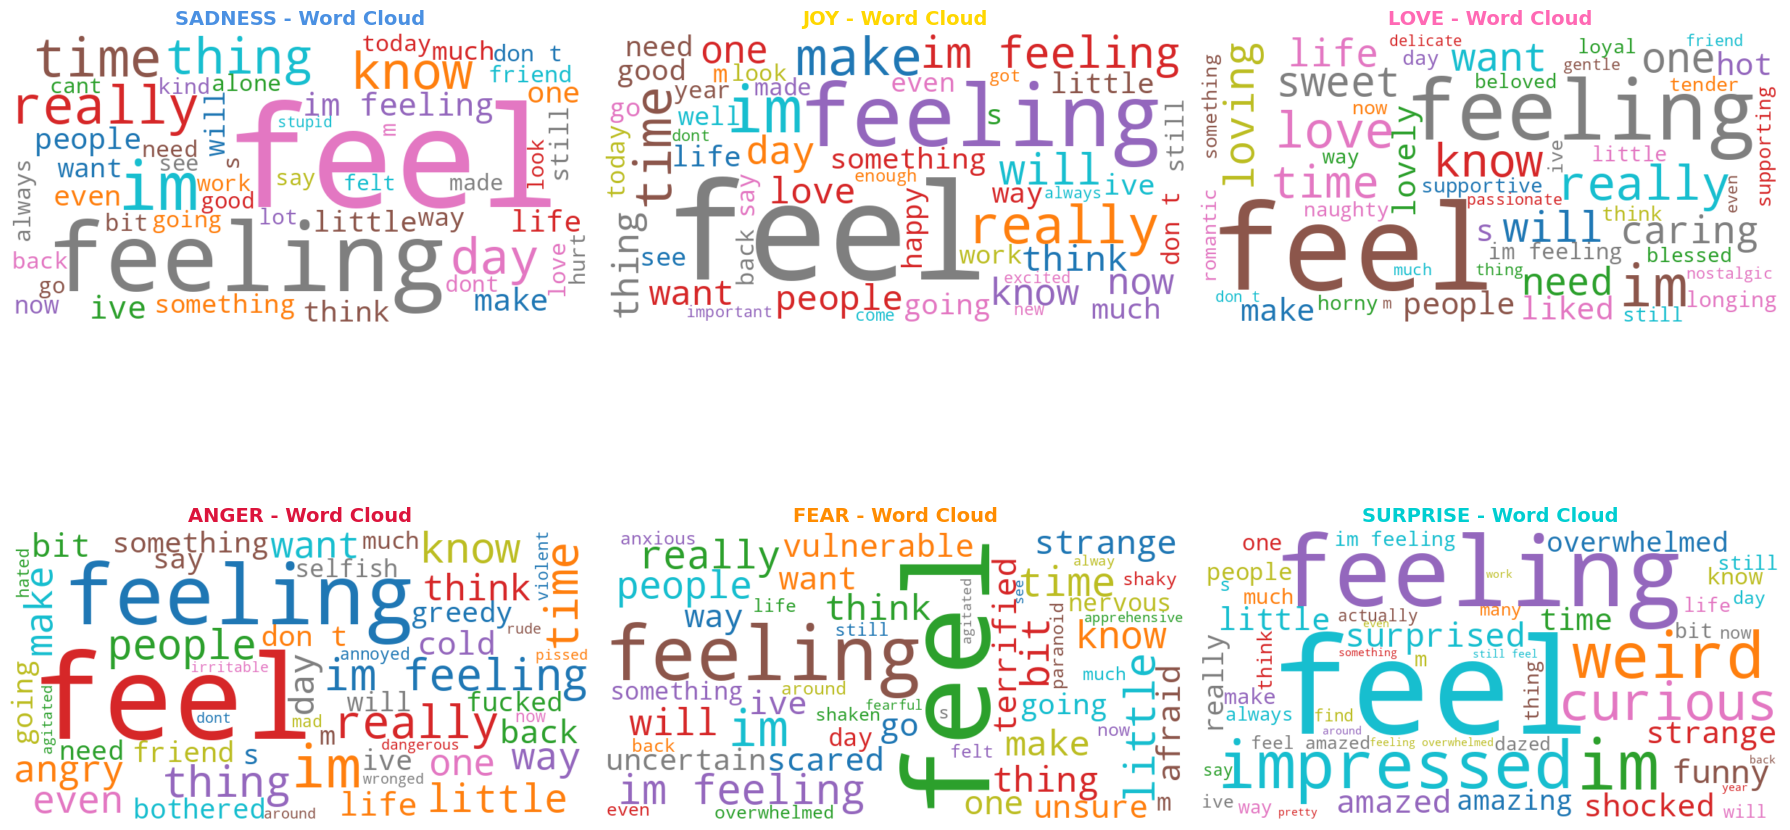

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from wordcloud import WordCloud
from collections import Counter

print("\n" + "=" * 60)
print("GENERATING ADDITIONAL VISUALIZATIONS")
print("=" * 60)

print("\n[1] Creating Word Clouds per Emotion...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

emotion_labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
colors = ['#4A90E2', '#FFD700', '#FF69B4', '#DC143C', '#FF8C00', '#00CED1']

for idx, (emotion, color) in enumerate(zip(emotion_labels, colors)):
    emotion_texts = train_data[train_data['label_name'] == emotion]['text'].str.cat(sep=' ')
    
    wordcloud = WordCloud(
        width=800, 
        height=400,
        background_color='white',
        colormap='tab10',
        max_words=50,
        relative_scaling=0.5,
        min_font_size=10
    ).generate(emotion_texts)
    
    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].set_title(f'{emotion.upper()} - Word Cloud', 
                        fontsize=14, fontweight='bold', color=color)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


[2] Analyzing Top Words per Emotion...


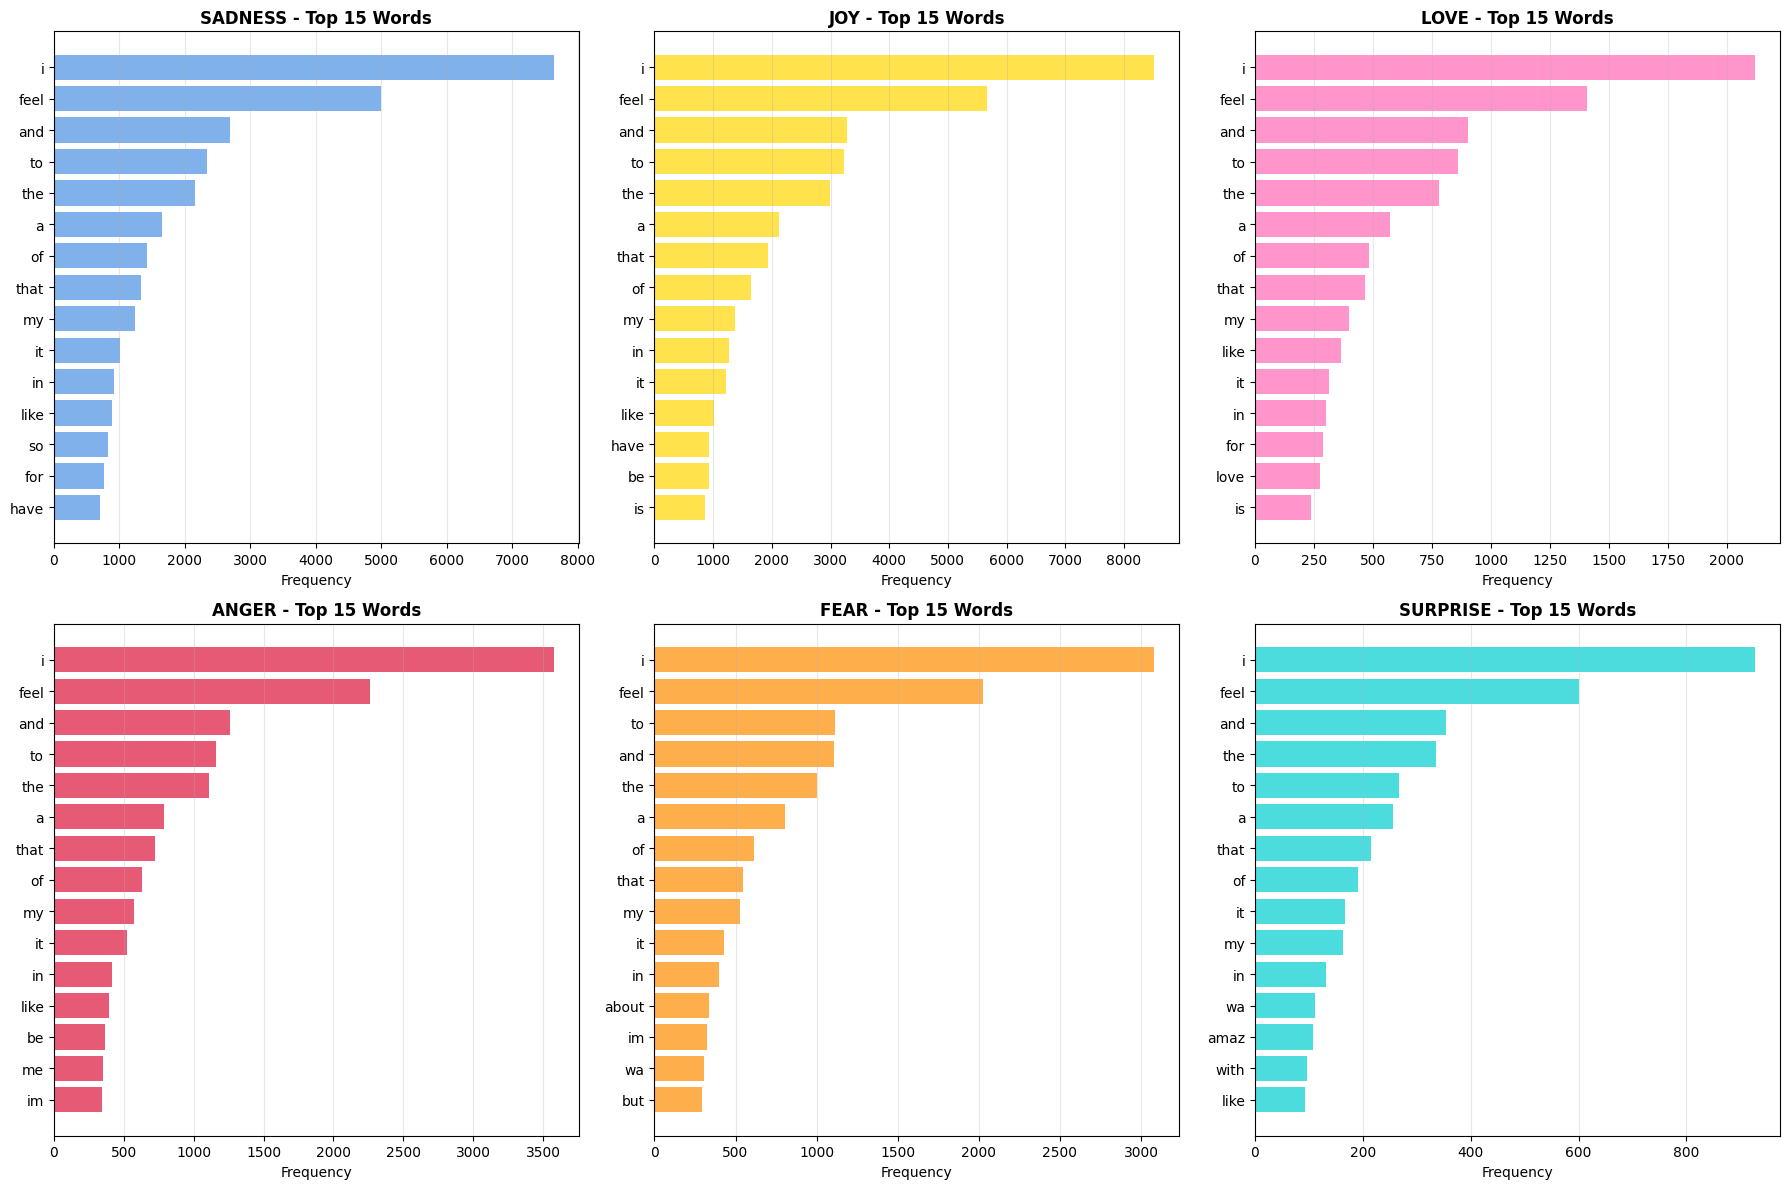

In [47]:
print("\n[2] Analyzing Top Words per Emotion...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, emotion in enumerate(emotion_labels):
    emotion_texts = train_data[train_data['label_name'] == emotion]['text_stemmed']
    all_words = ' '.join(emotion_texts).split()
    
    word_counts = Counter(all_words).most_common(15)
    words, counts = zip(*word_counts)
    
    axes[idx].barh(range(len(words)), counts, color=colors[idx], alpha=0.7)
    axes[idx].set_yticks(range(len(words)))
    axes[idx].set_yticklabels(words)
    axes[idx].invert_yaxis()
    axes[idx].set_xlabel('Frequency', fontsize=10)
    axes[idx].set_title(f'{emotion.upper()} - Top 15 Words', 
                        fontsize=12, fontweight='bold')
    axes[idx].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


[3] Text Length Distribution per Emotion...


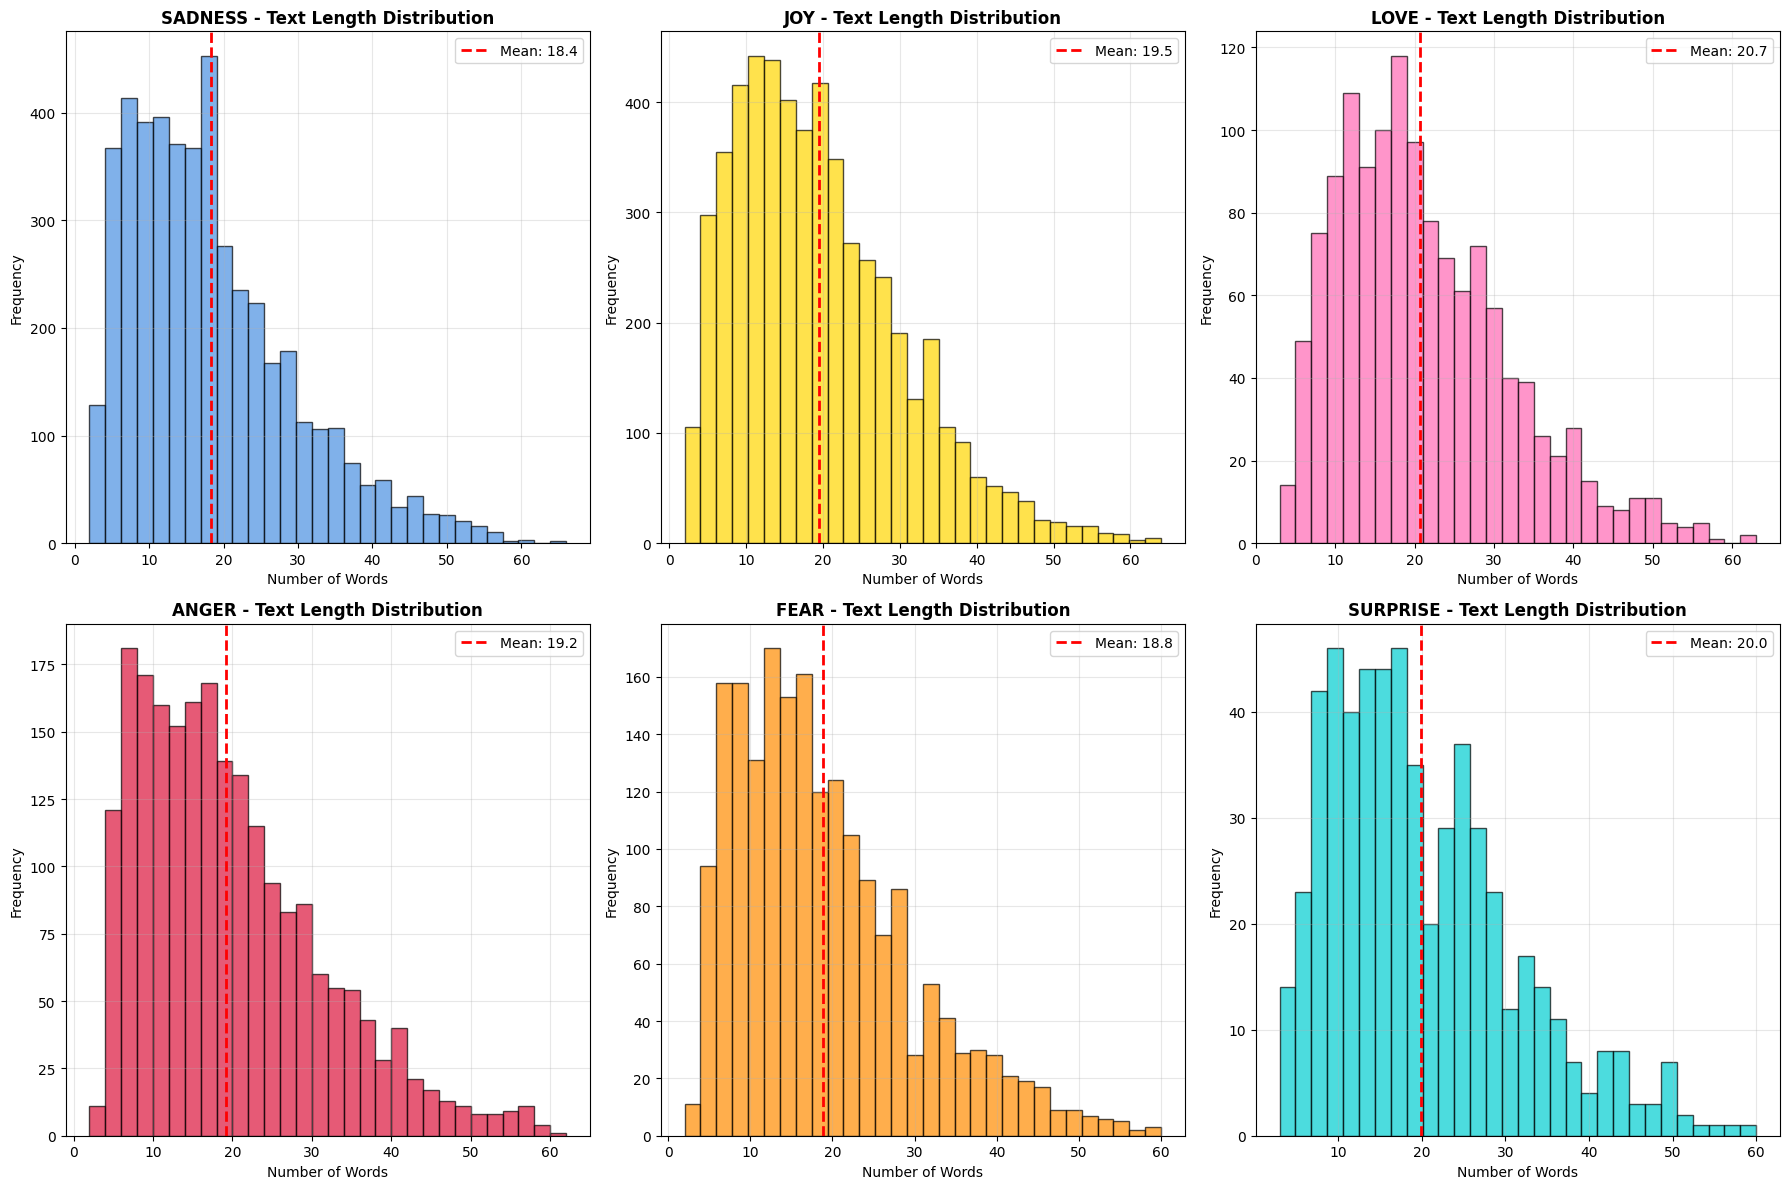

In [48]:
print("\n[3] Text Length Distribution per Emotion...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, emotion in enumerate(emotion_labels):
    emotion_data = train_data[train_data['label_name'] == emotion]
    text_lengths = emotion_data['text_length']
    
    axes[idx].hist(text_lengths, bins=30, color=colors[idx], 
                   alpha=0.7, edgecolor='black')
    axes[idx].axvline(text_lengths.mean(), color='red', 
                      linestyle='--', linewidth=2, label=f'Mean: {text_lengths.mean():.1f}')
    axes[idx].set_xlabel('Number of Words', fontsize=10)
    axes[idx].set_ylabel('Frequency', fontsize=10)
    axes[idx].set_title(f'{emotion.upper()} - Text Length Distribution', 
                        fontsize=12, fontweight='bold')
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()


[4] Comprehensive Learning Curves...


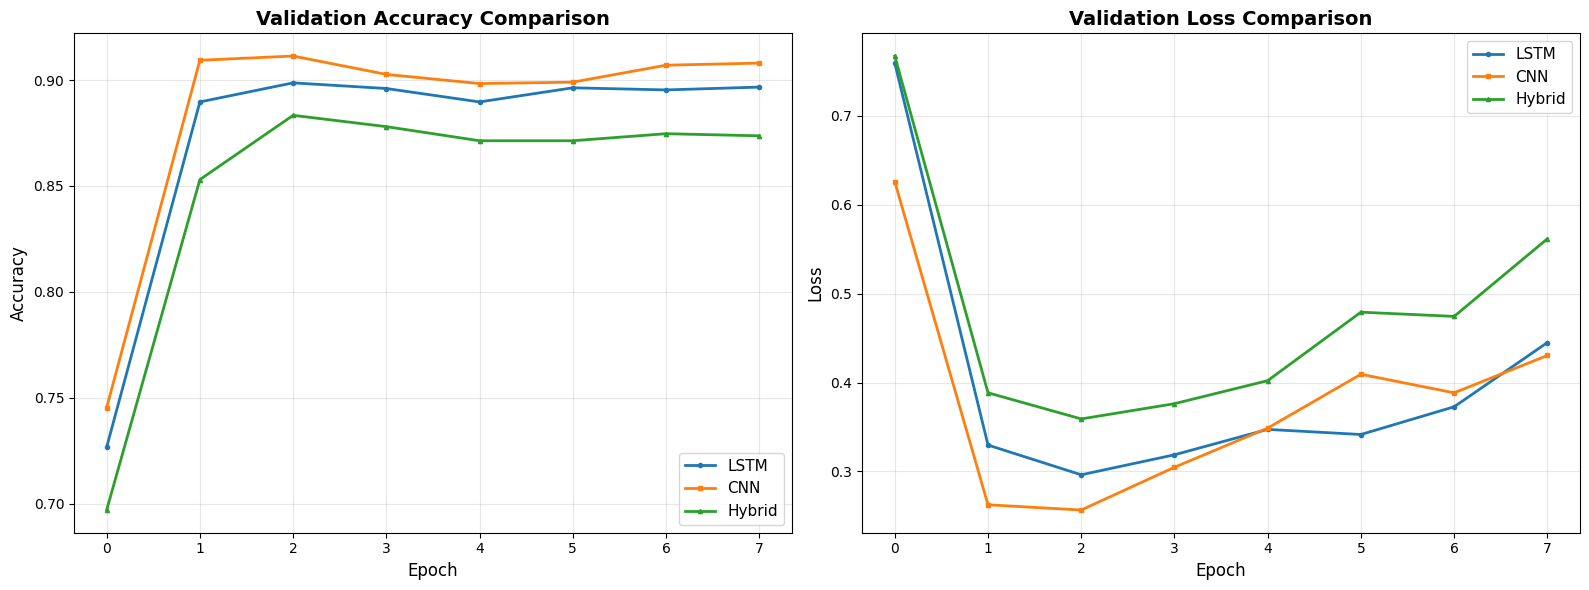

In [49]:
print("\n[4] Comprehensive Learning Curves...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(history_lstm.history['val_accuracy'], 
             label='LSTM', linewidth=2, marker='o', markersize=3)
axes[0].plot(history_cnn.history['val_accuracy'], 
             label='CNN', linewidth=2, marker='s', markersize=3)
axes[0].plot(history_hybrid.history['val_accuracy'], 
             label='Hybrid', linewidth=2, marker='^', markersize=3)
axes[0].set_title('Validation Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

axes[1].plot(history_lstm.history['val_loss'], 
             label='LSTM', linewidth=2, marker='o', markersize=3)
axes[1].plot(history_cnn.history['val_loss'], 
             label='CNN', linewidth=2, marker='s', markersize=3)
axes[1].plot(history_hybrid.history['val_loss'], 
             label='Hybrid', linewidth=2, marker='^', markersize=3)
axes[1].set_title('Validation Loss Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


[5] Per-Class Performance Analysis...


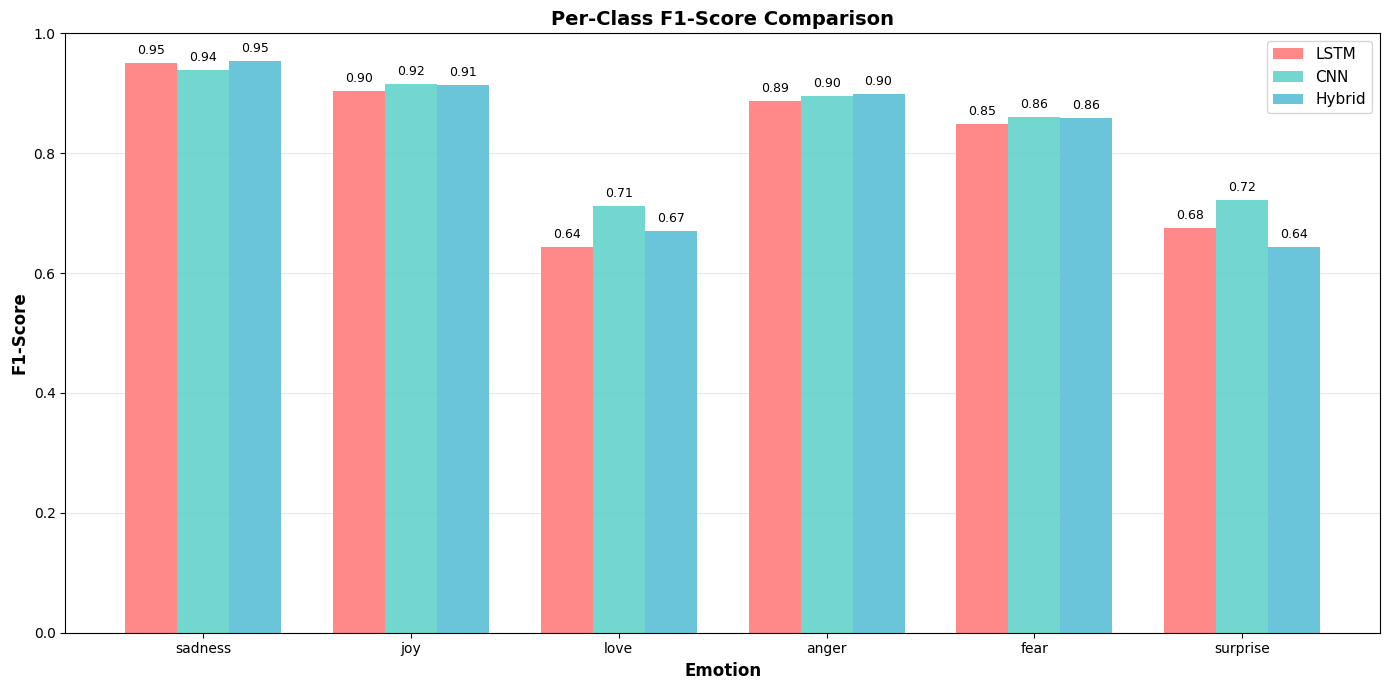

In [50]:
print("\n[5] Per-Class Performance Analysis...")

from sklearn.metrics import classification_report

report_lstm = classification_report(y_test, y_pred_lstm, 
                                    target_names=emotion_labels, output_dict=True)
report_cnn = classification_report(y_test, y_pred_cnn, 
                                   target_names=emotion_labels, output_dict=True)
report_hybrid = classification_report(y_test, y_pred_hybrid, 
                                      target_names=emotion_labels, output_dict=True)

f1_lstm = [report_lstm[label]['f1-score'] for label in emotion_labels]
f1_cnn = [report_cnn[label]['f1-score'] for label in emotion_labels]
f1_hybrid = [report_hybrid[label]['f1-score'] for label in emotion_labels]

x = np.arange(len(emotion_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width, f1_lstm, width, label='LSTM', color='#FF6B6B', alpha=0.8)
bars2 = ax.bar(x, f1_cnn, width, label='CNN', color='#4ECDC4', alpha=0.8)
bars3 = ax.bar(x + width, f1_hybrid, width, label='Hybrid', color='#45B7D1', alpha=0.8)

ax.set_xlabel('Emotion', fontsize=12, fontweight='bold')
ax.set_ylabel('F1-Score', fontsize=12, fontweight='bold')
ax.set_title('Per-Class F1-Score Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(emotion_labels)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


[6] Prediction Confidence Distribution...


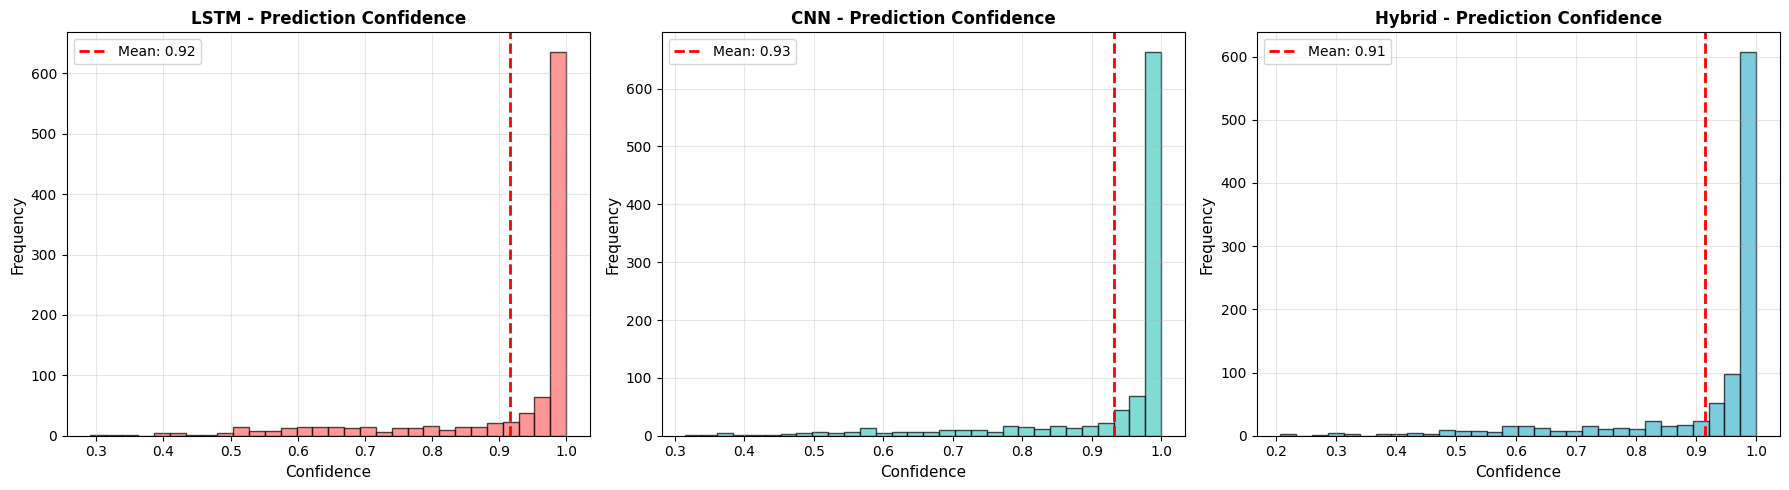

In [51]:
print("\n[6] Prediction Confidence Distribution...")

prob_lstm = lstm_model.predict(X_test, verbose=0)
prob_cnn = cnn_model.predict(X_test, verbose=0)
prob_hybrid = hybrid_model.predict(X_test, verbose=0)

conf_lstm = np.max(prob_lstm, axis=1)
conf_cnn = np.max(prob_cnn, axis=1)
conf_hybrid = np.max(prob_hybrid, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(conf_lstm, bins=30, color='#FF6B6B', alpha=0.7, edgecolor='black')
axes[0].axvline(conf_lstm.mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Mean: {conf_lstm.mean():.2f}')
axes[0].set_xlabel('Confidence', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('LSTM - Prediction Confidence', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(conf_cnn, bins=30, color='#4ECDC4', alpha=0.7, edgecolor='black')
axes[1].axvline(conf_cnn.mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Mean: {conf_cnn.mean():.2f}')
axes[1].set_xlabel('Confidence', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('CNN - Prediction Confidence', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].hist(conf_hybrid, bins=30, color='#45B7D1', alpha=0.7, edgecolor='black')
axes[2].axvline(conf_hybrid.mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Mean: {conf_hybrid.mean():.2f}')
axes[2].set_xlabel('Confidence', fontsize=11)
axes[2].set_ylabel('Frequency', fontsize=11)
axes[2].set_title('Hybrid - Prediction Confidence', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


[7] Correct vs Incorrect Predictions Analysis...


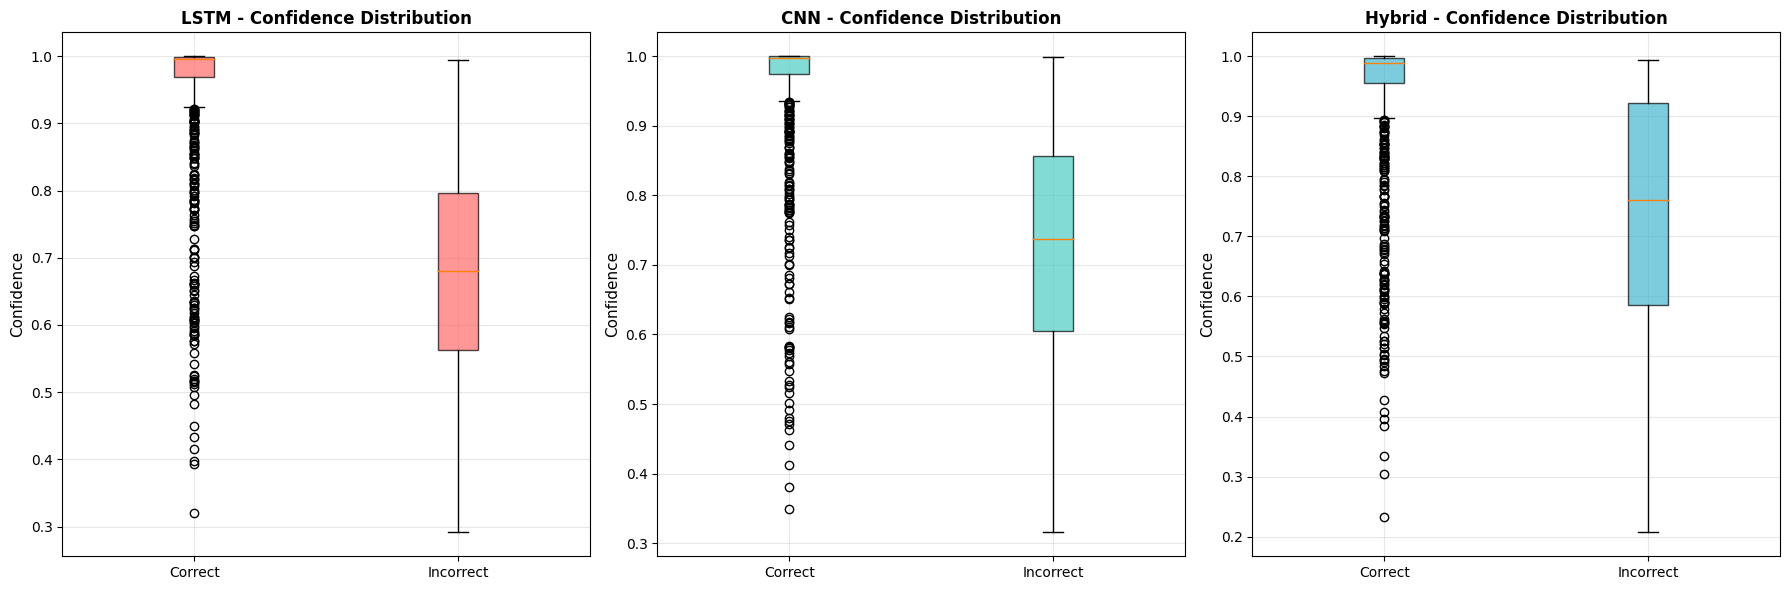

In [52]:
print("\n[7] Correct vs Incorrect Predictions Analysis...")

correct_lstm = (y_pred_lstm == y_test).astype(int)
correct_cnn = (y_pred_cnn == y_test).astype(int)
correct_hybrid = (y_pred_hybrid == y_test).astype(int)

conf_correct_lstm = conf_lstm[correct_lstm == 1]
conf_incorrect_lstm = conf_lstm[correct_lstm == 0]

conf_correct_cnn = conf_cnn[correct_cnn == 1]
conf_incorrect_cnn = conf_cnn[correct_cnn == 0]

conf_correct_hybrid = conf_hybrid[correct_hybrid == 1]
conf_incorrect_hybrid = conf_hybrid[correct_hybrid == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

data_lstm = [conf_correct_lstm, conf_incorrect_lstm]
axes[0].boxplot(data_lstm, labels=['Correct', 'Incorrect'], 
                patch_artist=True, 
                boxprops=dict(facecolor='#FF6B6B', alpha=0.7))
axes[0].set_ylabel('Confidence', fontsize=11)
axes[0].set_title('LSTM - Confidence Distribution', fontsize=12, fontweight='bold')
axes[0].grid(alpha=0.3)

data_cnn = [conf_correct_cnn, conf_incorrect_cnn]
axes[1].boxplot(data_cnn, labels=['Correct', 'Incorrect'],
                patch_artist=True,
                boxprops=dict(facecolor='#4ECDC4', alpha=0.7))
axes[1].set_ylabel('Confidence', fontsize=11)
axes[1].set_title('CNN - Confidence Distribution', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)

data_hybrid = [conf_correct_hybrid, conf_incorrect_hybrid]
axes[2].boxplot(data_hybrid, labels=['Correct', 'Incorrect'],
                patch_artist=True,
                boxprops=dict(facecolor='#45B7D1', alpha=0.7))
axes[2].set_ylabel('Confidence', fontsize=11)
axes[2].set_title('Hybrid - Confidence Distribution', fontsize=12, fontweight='bold')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


[8] Ensemble Methods Performance Radar Chart...


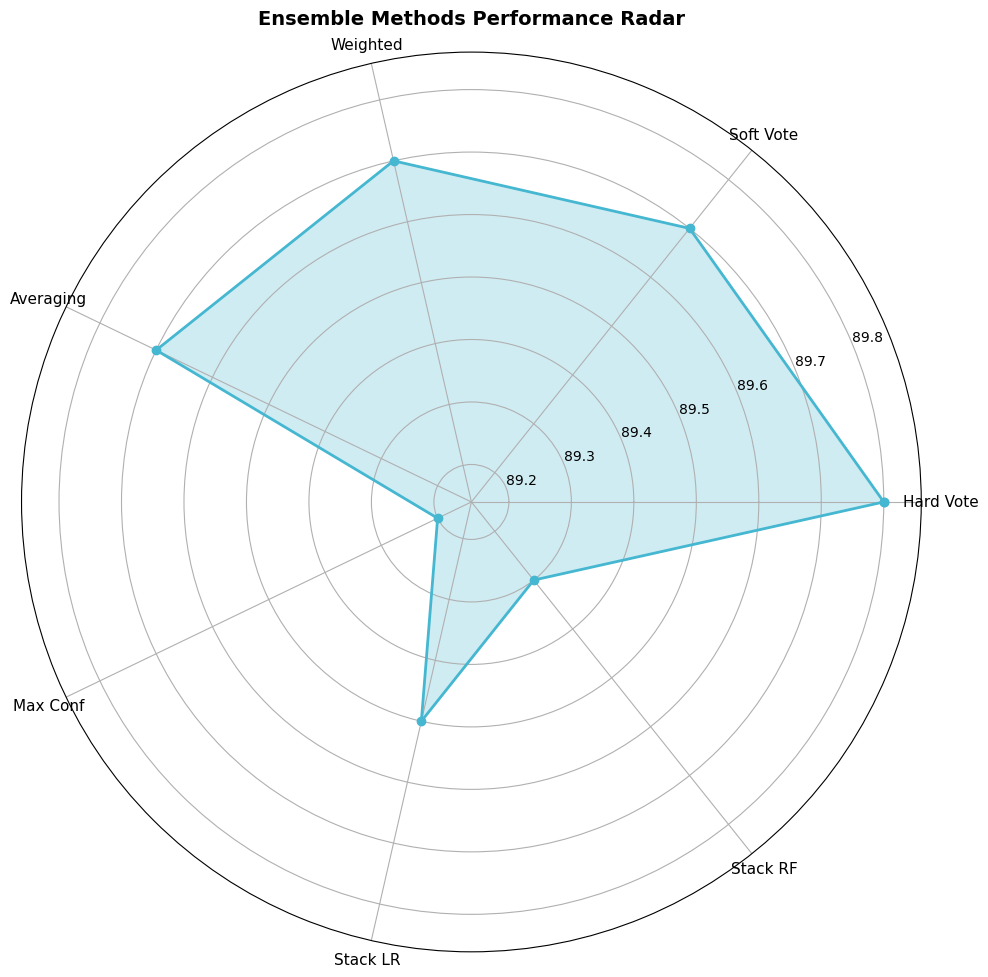

In [53]:
print("\n[8] Ensemble Methods Performance Radar Chart...")

from math import pi

methods = ['Hard Vote', 'Soft Vote', 'Weighted', 'Averaging', 'Max Conf', 'Stack LR', 'Stack RF']
accuracies_ensemble = [acc_hard, acc_soft, acc_weighted, acc_avg, acc_maxconf, acc_stack_lr, acc_stack_rf]

accuracies_normalized = [acc * 100 for acc in accuracies_ensemble]

angles = [n / float(len(methods)) * 2 * pi for n in range(len(methods))]
accuracies_normalized += accuracies_normalized[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))
ax.plot(angles, accuracies_normalized, 'o-', linewidth=2, color='#45B7D1')
ax.fill(angles, accuracies_normalized, alpha=0.25, color='#45B7D1')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(methods, size=11)
min_acc = min(accuracies_normalized[:-1])
max_acc = max(accuracies_normalized[:-1])
margin = (max_acc - min_acc) * 0.1 or 2
ax.set_ylim(max(0, min_acc - margin), min(100, max_acc + margin))
ax.set_title('Ensemble Methods Performance Radar', 
             size=14, fontweight='bold', pad=20)
ax.grid(True)

plt.tight_layout()
plt.show()


[9] Most Confused Emotion Pairs...


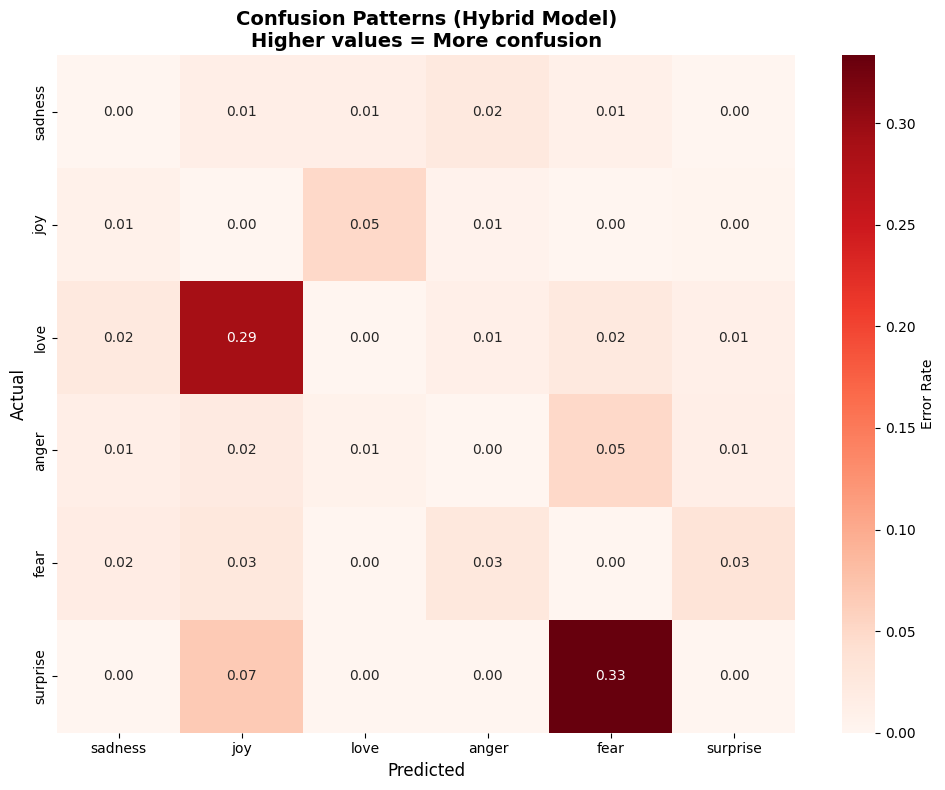

In [54]:
print("\n[9] Most Confused Emotion Pairs...")

cm_normalized = cm_hybrid.astype('float') / cm_hybrid.sum(axis=1)[:, np.newaxis]

cm_errors = cm_normalized.copy()
np.fill_diagonal(cm_errors, 0)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_errors, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=emotion_labels, yticklabels=emotion_labels,
            cbar_kws={'label': 'Error Rate'})
ax.set_title('Confusion Patterns (Hybrid Model)\nHigher values = More confusion', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)

plt.tight_layout()
plt.show()


[10] Creating Summary Dashboard...


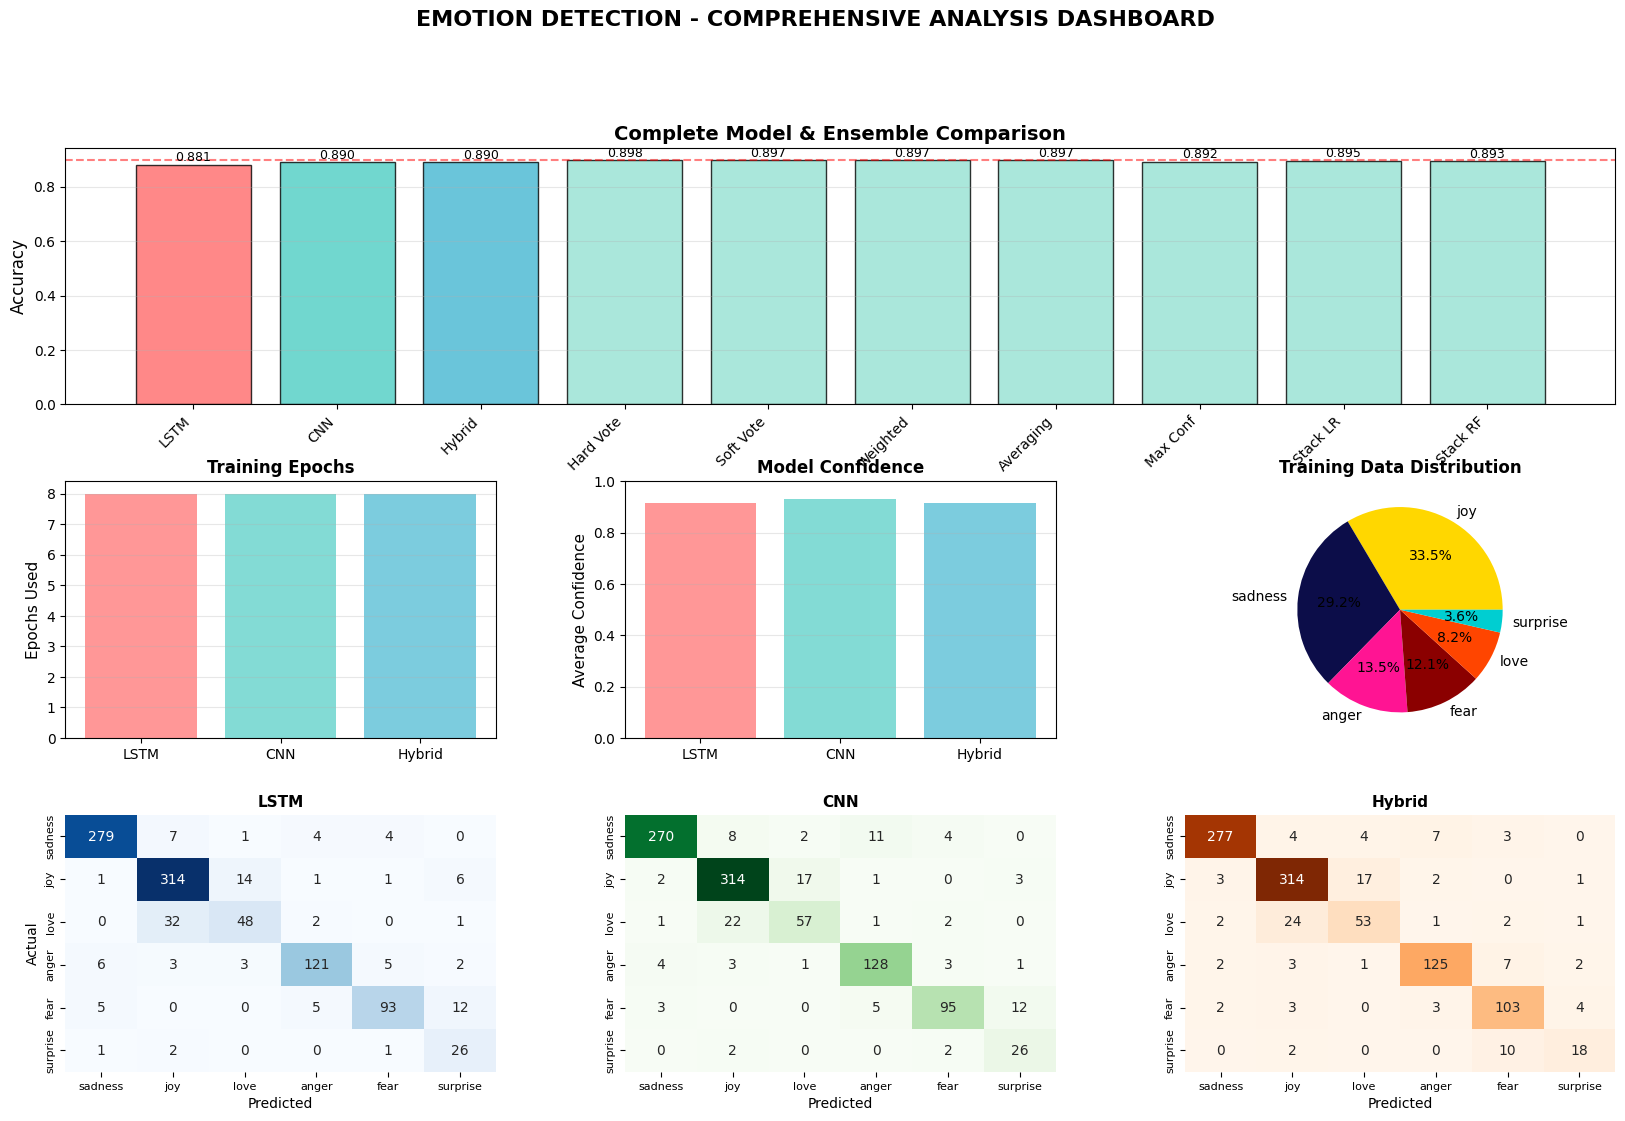

In [55]:
print("\n[10] Creating Summary Dashboard...")

fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

ax1 = fig.add_subplot(gs[0, :])
all_models = ['LSTM', 'CNN', 'Hybrid', 'Hard Vote', 'Soft Vote', 
              'Weighted', 'Averaging', 'Max Conf', 'Stack LR', 'Stack RF']
all_accs = [test_acc_lstm, test_acc_cnn, test_acc_hybrid] + accuracies_ensemble

colors_all = ['#FF6B6B', '#4ECDC4', '#45B7D1'] + ['#95E1D3']*7
bars = ax1.bar(range(len(all_models)), all_accs, color=colors_all, alpha=0.8, edgecolor='black')
ax1.set_xticks(range(len(all_models)))
ax1.set_xticklabels(all_models, rotation=45, ha='right')
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Complete Model & Ensemble Comparison', fontsize=14, fontweight='bold')
ax1.axhline(y=max(all_accs), color='red', linestyle='--', alpha=0.5)
ax1.grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, all_accs):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.002,
             f'{acc:.3f}', ha='center', va='bottom', fontsize=9, rotation=0)

ax2 = fig.add_subplot(gs[1, 0])
epochs_used = [len(history_lstm.history['loss']), 
               len(history_cnn.history['loss']), 
               len(history_hybrid.history['loss'])]
ax2.bar(['LSTM', 'CNN', 'Hybrid'], epochs_used, 
        color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.7)
ax2.set_ylabel('Epochs Used', fontsize=11)
ax2.set_title('Training Epochs', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

ax3 = fig.add_subplot(gs[1, 1])
avg_confs = [conf_lstm.mean(), conf_cnn.mean(), conf_hybrid.mean()]
ax3.bar(['LSTM', 'CNN', 'Hybrid'], avg_confs,
        color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.7)
ax3.set_ylabel('Average Confidence', fontsize=11)
ax3.set_title('Model Confidence', fontsize=12, fontweight='bold')
ax3.set_ylim([0, 1])
ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 2])
class_counts = train_data['label_name'].value_counts()
ax4.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
        colors=['#FFD700', '#0c0d49', '#FF1493', '#8B0000', '#FF4500', '#00CED1'])
ax4.set_title('Training Data Distribution', fontsize=12, fontweight='bold')

for idx, (model_name, cm, color) in enumerate([
    ('LSTM', cm_lstm, 'Blues'),
    ('CNN', cm_cnn, 'Greens'),
    ('Hybrid', cm_hybrid, 'Oranges')
]):
    ax = fig.add_subplot(gs[2, idx])
    sns.heatmap(cm, annot=True, fmt='d', cmap=color, cbar=False,
                xticklabels=emotion_labels, yticklabels=emotion_labels, ax=ax)
    ax.set_title(f'{model_name}', fontsize=11, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=10)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.tick_params(labelsize=8)

plt.suptitle('EMOTION DETECTION - COMPREHENSIVE ANALYSIS DASHBOARD', 
             fontsize=16, fontweight='bold', y=0.995)
plt.show()